# 08c — Day 8c Evaluation: Ensembling a Better HuBERT Pipeline with WavLM

**Standalone**, same pattern as every other evaluation notebook. Follow-up to Day 8b: that notebook
ensembled *plain* HuBERT L12 (0.611) with *plain* WavLM L6 (0.663) via OOF-probability averaging and
got the project's best result so far (0.676). This notebook asks the natural next question: does
feeding the ensemble a **better** HuBERT pipeline — the ones augmentation/fusion already improved —
push it even higher, or does averaging with a stronger-but-more-correlated signal help less than
averaging with two independently-weaker ones did?

**Two configurations, isolated from each other, both reusing already-established techniques rather
than introducing new ones (no PCA here — Day 6 and Day 8a both already found PCA hurts once
augmentation is involved, so it's deliberately left out to keep this notebook focused on the one
new variable: which HuBERT pipeline feeds the ensemble):**

- **Config A (recording-grain, N=280):** average WavLM L6 (plain, Day 7) with **augmented** HuBERT
  L12 (no fusion, Day 5/6's config #1 -- 0.639) instead of plain HuBERT (0.611). Same grain as
  Day 8b's ensemble, so the two are directly comparable -- swapping only which HuBERT pipeline
  feeds the average.
- **Config B (session-grain, N=92):** average WavLM L6 aggregated up to session level (mean of a
  session's 3 activity-level OOF scores -- the same post-hoc session-fusion technique this project's
  very first baseline used) with Day 6's actual confirmed winning pipeline -- **augmented HuBERT L12
  + session-fusion (0.651)**. This is "Day 6's confirmed pipeline" specifically, at its native
  session grain, so no information is thrown away collapsing it down to recording grain.

**Why the cross-grain step in Config B is safe:** WavLM's recording-level OOF scores are already
leak-free (each came from a model that never saw that recording's participant); averaging three of
them per session is a fixed, deterministic post-hoc operation, not a new model fit -- it introduces
no new leakage risk, same reasoning as the project's original session-level fusion sanity check.

**No permutation test here** — reserved for Day 10's single finalized candidate.

**Inputs needed (Kaggle "Add Input") — 4 total:**
1. The **`Fatigue_data`** dataset — for `labels.csv`.
2. **Day 3's `01_features.ipynb`** output — for `hubert_base_all_layers.parquet`.
3. **Day 5's `05_features_hubert_augmented.ipynb`** output — for `hubert_layer12_speed_augmented.parquet`.
4. **Day 7's `07_features_wavlm.ipynb`** output — for `wavlm_base_plus_all_layers.parquet`.

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_SEED = 42
HUBERT_LAYER = 12
WAVLM_LAYER = 6
ACTIVITY_ORDER = ["read_aloud", "read_aloud_nonsense", "describe_picture"]

LABELS_CSV = next(Path("/kaggle/input").rglob("labels.csv"))
HUBERT_ALL_LAYERS_PARQUET = next(Path("/kaggle/input").rglob("hubert_base_all_layers.parquet"))
HUBERT_AUGMENTED_PARQUET = next(Path("/kaggle/input").rglob("hubert_layer12_speed_augmented.parquet"))
WAVLM_ALL_LAYERS_PARQUET = next(Path("/kaggle/input").rglob("wavlm_base_plus_all_layers.parquet"))

print(f"LABELS_CSV                = {LABELS_CSV}")
print(f"HUBERT_ALL_LAYERS_PARQUET = {HUBERT_ALL_LAYERS_PARQUET}")
print(f"HUBERT_AUGMENTED_PARQUET  = {HUBERT_AUGMENTED_PARQUET}")
print(f"WAVLM_ALL_LAYERS_PARQUET  = {WAVLM_ALL_LAYERS_PARQUET}")

labels = pd.read_csv(LABELS_CSV)
LABEL_MAP = {"non_fatigued": 0, "fatigued": 1}

LABELS_CSV                = /kaggle/input/datasets/tapudatta/fatigue-data/project_data/labels.csv
HUBERT_ALL_LAYERS_PARQUET = /kaggle/input/notebooks/tappu1/notebook1-day3/features/hubert_base_all_layers.parquet
HUBERT_AUGMENTED_PARQUET  = /kaggle/input/notebooks/tapudatta/day5-aug-features/features/hubert_layer12_speed_augmented.parquet
WAVLM_ALL_LAYERS_PARQUET  = /kaggle/input/notebooks/tapudatta/notebook1-day7/features/wavlm_base_plus_all_layers.parquet


## 1. Build HuBERT Augmented Dataset (recording grain)

Identical to `06_evaluate_combined.ipynb` section 1 — original layer-12 embeddings (tagged
`speed_factor=1.0`) plus the 0.9x/1.1x augmented copies, 840 rows total, 280 of them original.

In [2]:
hubert_all_layers = pd.read_parquet(HUBERT_ALL_LAYERS_PARQUET)
hubert_augmented = pd.read_parquet(HUBERT_AUGMENTED_PARQUET)

hubert_layer_cols = [c for c in hubert_all_layers.columns if c.startswith(f"layer{HUBERT_LAYER}_emb_")]
assert len(hubert_layer_cols) == 1536
original_hubert = hubert_all_layers[["filename"] + hubert_layer_cols].copy()
original_hubert.columns = ["filename"] + [f"emb_{i}" for i in range(1536)]
original_hubert["speed_factor"] = 1.0

hubert_augmented = hubert_augmented.rename(columns={"source_filename": "filename"})
hubert_combined_emb = pd.concat([original_hubert, hubert_augmented], ignore_index=True, sort=False)
assert len(hubert_combined_emb) == 280 * 3, f"expected 840 rows, got {len(hubert_combined_emb)}"

df_aug_hubert = labels.merge(hubert_combined_emb, on="filename", how="inner").reset_index(drop=True)
assert len(df_aug_hubert) == 280 * 3, f"expected 840 rows after merge, got {len(df_aug_hubert)}"
df_aug_hubert["y"] = df_aug_hubert["label"].map(LABEL_MAP)
assert df_aug_hubert["y"].isna().sum() == 0
df_aug_hubert["is_original"] = df_aug_hubert["speed_factor"] == 1.0

hubert_emb_cols = [c for c in df_aug_hubert.columns if c.startswith("emb_")]
X_hubert_aug = df_aug_hubert[hubert_emb_cols].to_numpy()
y_hubert_aug = df_aug_hubert["y"].to_numpy()
groups_hubert_aug = df_aug_hubert["participant_id"].to_numpy()
is_original_hubert_aug = df_aug_hubert["is_original"].to_numpy()

print(f"X_hubert_aug: {X_hubert_aug.shape}  (original rows: {is_original_hubert_aug.sum()}, "
      f"augmented rows: {(~is_original_hubert_aug).sum()})")

X_hubert_aug: (840, 1536)  (original rows: 280, augmented rows: 560)


## 2. Build WavLM Plain Dataset (recording grain)

Plain, un-augmented layer-6 embeddings, same as Day 7/8b — 280 rows. `is_original_wavlm` is set to
all-`True` so the same augmentation-aware CV function used for HuBERT can be reused unchanged for
WavLM too (with no augmented rows, its masking logic reduces exactly to a plain nested LOSO).

In [3]:
wavlm_all_layers = pd.read_parquet(WAVLM_ALL_LAYERS_PARQUET)
wavlm_layer_cols = [c for c in wavlm_all_layers.columns if c.startswith(f"layer{WAVLM_LAYER}_emb_")]
assert len(wavlm_layer_cols) == 1536
wavlm_emb_only = wavlm_all_layers[["filename"] + wavlm_layer_cols].copy()
wavlm_emb_only.columns = ["filename"] + [f"emb_{i}" for i in range(1536)]

df_wavlm = labels.merge(wavlm_emb_only, on="filename", how="inner").reset_index(drop=True)
assert len(df_wavlm) == 280, f"expected 280 rows, got {len(df_wavlm)}"
df_wavlm["y"] = df_wavlm["label"].map(LABEL_MAP)
assert df_wavlm["y"].isna().sum() == 0

wavlm_emb_cols = [c for c in df_wavlm.columns if c.startswith("emb_")]
X_wavlm = df_wavlm[wavlm_emb_cols].to_numpy()
y_wavlm = df_wavlm["y"].to_numpy()
groups_wavlm = df_wavlm["participant_id"].to_numpy()
is_original_wavlm = np.ones(len(df_wavlm), dtype=bool)

print(f"X_wavlm: {X_wavlm.shape}")

X_wavlm: (280, 1536)


## 3. Shared Candidates & Augmentation-Aware Nested CV (duplicated from `06_evaluate_combined.ipynb`)

Plain 10-candidate set only (no PCA) — deliberately, per the rationale above. `nested_loso_cv_augmented_variant`
is unchanged from Day 6/8a; it works identically for WavLM's all-`True` `is_original` array.

In [4]:
CANDIDATE_CS = [0.001, 0.01, 0.1, 1.0, 10.0]


def build_pipeline(model_name: str, c: float) -> Pipeline:
    if model_name == "logreg":
        clf = LogisticRegression(C=c, max_iter=5000, class_weight="balanced")
    elif model_name == "linsvc":
        clf = LinearSVC(C=c, max_iter=10000, class_weight="balanced")
    else:
        raise ValueError(model_name)
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


def make_candidates():
    return [
        (f"{name}_C={c}", build_pipeline(name, c))
        for name in ["logreg", "linsvc"]
        for c in CANDIDATE_CS
    ]


def score_fn(fitted_pipeline: Pipeline, X_in: np.ndarray) -> np.ndarray:
    clf = fitted_pipeline.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        return fitted_pipeline.predict_proba(X_in)[:, 1]
    return fitted_pipeline.decision_function(X_in)


def best_threshold(scores: np.ndarray, y_true: np.ndarray) -> float:
    best_t, best_ba = 0.5, -1.0
    for t in np.unique(scores):
        ba = balanced_accuracy_score(y_true, (scores >= t).astype(int))
        if ba > best_ba:
            best_ba, best_t = ba, t
    return best_t

In [5]:
def nested_loso_cv_augmented_variant(X, y, groups, is_original, make_candidates_fn,
                                      n_inner_splits=6, expected_n_scored=None):
    participants = np.unique(groups)
    oof_scores = np.full(len(y), np.nan)
    fold_records = []
    n_outer_checked, n_inner_checked = 0, 0

    for test_participant in participants:
        outer_test_mask = (groups == test_participant) & is_original
        outer_train_mask = groups != test_participant
        assert not (set(groups[outer_train_mask]) & set(groups[outer_test_mask])), \
            f"outer leakage: {test_participant} present in both outer train and test"
        n_outer_checked += 1

        X_tr, y_tr, g_tr = X[outer_train_mask], y[outer_train_mask], groups[outer_train_mask]
        is_orig_tr = is_original[outer_train_mask]
        X_te = X[outer_test_mask]

        candidates = make_candidates_fn()
        cand_aucs = {i: [] for i in range(len(candidates))}
        cand_scores = {i: [] for i in range(len(candidates))}
        cand_labels = {i: [] for i in range(len(candidates))}

        gkf = GroupKFold(n_splits=n_inner_splits)
        for inner_tr_idx, inner_val_idx in gkf.split(X_tr, y_tr, groups=g_tr):
            assert not (set(g_tr[inner_tr_idx]) & set(g_tr[inner_val_idx])), \
                f"inner leakage within outer fold {test_participant}"
            n_inner_checked += 1

            inner_val_idx = inner_val_idx[is_orig_tr[inner_val_idx]]
            if len(inner_val_idx) == 0:
                continue
            X_itr, y_itr = X_tr[inner_tr_idx], y_tr[inner_tr_idx]
            X_ival, y_ival = X_tr[inner_val_idx], y_tr[inner_val_idx]
            if len(np.unique(y_itr)) < 2 or len(np.unique(y_ival)) < 2:
                continue

            for i, (_, pipe) in enumerate(candidates):
                fitted = clone(pipe).fit(X_itr, y_itr)
                s = score_fn(fitted, X_ival)
                cand_aucs[i].append(roc_auc_score(y_ival, s))
                cand_scores[i].append(s)
                cand_labels[i].append(y_ival)

        mean_aucs = {i: np.mean(v) for i, v in cand_aucs.items() if v}
        best_i = max(mean_aucs, key=mean_aucs.get)
        best_label, best_template = candidates[best_i]

        final_pipe = clone(best_template).fit(X_tr, y_tr)
        test_scores = score_fn(final_pipe, X_te)
        oof_scores[np.where(outer_test_mask)[0]] = test_scores

        fold_records.append({"test_participant": test_participant, "chosen_label": best_label,
                              "inner_cv_auc": mean_aucs[best_i]})

    print(f"  Verified zero participant overlap: {n_outer_checked} outer folds, "
          f"{n_inner_checked} inner GroupKFold(6) splits.")
    n_scored = int(np.sum(~np.isnan(oof_scores)))
    print(f"  Scored {n_scored} original rows.")
    if expected_n_scored is not None:
        assert n_scored == expected_n_scored, f"expected {expected_n_scored} scored rows, got {n_scored}"
    return oof_scores, pd.DataFrame(fold_records)


def bootstrap_auc_ci(participant_ids, y_true, scores, n_boot=1000, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    participants = np.unique(participant_ids)
    idx_by_participant = {p: np.where(participant_ids == p)[0] for p in participants}
    boot_aucs = []
    for _ in range(n_boot):
        sampled = rng.choice(participants, size=len(participants), replace=True)
        idx = np.concatenate([idx_by_participant[p] for p in sampled])
        y_boot, s_boot = y_true[idx], scores[idx]
        if len(np.unique(y_boot)) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_boot, s_boot))
    lo, hi = np.percentile(boot_aucs, [2.5, 97.5])
    return lo, hi, np.array(boot_aucs)


def report(name, y_true, scores, groups_arr):
    auc = roc_auc_score(y_true, scores)
    lo, hi, _ = bootstrap_auc_ci(groups_arr, y_true, scores)
    print(f"{name}: AUC={auc:.3f}  CI=[{lo:.3f}, {hi:.3f}]  N={len(y_true)}")
    return auc, lo, hi


results_log = []

## 4. Reproduce the Two Base Pipelines (sanity checks + source OOF scores)

Both should land close to their already-logged numbers. Their OOF scores (only the *scored*,
original-row positions) become the inputs to Config A's ensemble below.

In [6]:
oof_hubert_aug, _ = nested_loso_cv_augmented_variant(
    X_hubert_aug, y_hubert_aug, groups_hubert_aug, is_original_hubert_aug, make_candidates, expected_n_scored=280
)
# Filter to the scored (original) rows before computing AUC -- augmented rows are NaN by
# construction (never scored), same masking nested_loso_cv_augmented_variant's callers always apply.
auc, lo, hi = report(
    "Augmented HuBERT L12 (no fusion) -- sanity vs. Day 5/6: 0.639",
    y_hubert_aug[is_original_hubert_aug], oof_hubert_aug[is_original_hubert_aug], groups_hubert_aug[is_original_hubert_aug],
)
results_log.append({"variant": "Augmented HuBERT L12 (no fusion)", "auc": auc, "ci_lo": lo, "ci_hi": hi})

oof_wavlm, _ = nested_loso_cv_augmented_variant(
    X_wavlm, y_wavlm, groups_wavlm, is_original_wavlm, make_candidates, expected_n_scored=280
)
auc, lo, hi = report("WavLM L6 (plain) -- sanity vs. Day 7: 0.663", y_wavlm, oof_wavlm, groups_wavlm)
results_log.append({"variant": "WavLM L6 (plain)", "auc": auc, "ci_lo": lo, "ci_hi": hi})

# Recording-grain identity frames (filename -> score), used for Config A's merge below.
hubert_recording_scores = pd.DataFrame({
    "filename": df_aug_hubert.loc[is_original_hubert_aug, "filename"].to_numpy(),
    "y": y_hubert_aug[is_original_hubert_aug],
    "participant_id": groups_hubert_aug[is_original_hubert_aug],
    "score_hubert": oof_hubert_aug[is_original_hubert_aug],
})
wavlm_recording_scores = pd.DataFrame({
    "filename": df_wavlm["filename"].to_numpy(),
    "y": y_wavlm,
    "participant_id": groups_wavlm,
    "score_wavlm": oof_wavlm,
})

  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 280 original rows.
Augmented HuBERT L12 (no fusion) -- sanity vs. Day 5/6: 0.639: AUC=0.639  CI=[0.576, 0.705]  N=280
  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 280 original rows.
WavLM L6 (plain) -- sanity vs. Day 7: 0.663: AUC=0.663  CI=[0.600, 0.710]  N=280


## 5. Config A — Recording-Grain Ensemble: Augmented HuBERT L12 + WavLM L6

Average of two recording-grain OOF score arrays, merged explicitly on `filename` (not positional
concatenation) so pairing is correct regardless of internal row order.

In [7]:
merged_a = hubert_recording_scores.merge(
    wavlm_recording_scores[["filename", "score_wavlm"]], on="filename", how="inner"
)
assert len(merged_a) == 280, f"expected 280 matched recordings, got {len(merged_a)}"
merged_a["score_avg"] = (merged_a["score_hubert"] + merged_a["score_wavlm"]) / 2

auc_a, lo_a, hi_a = report(
    "Config A: Average(Augmented HuBERT L12, WavLM L6)",
    merged_a["y"].to_numpy(), merged_a["score_avg"].to_numpy(), merged_a["participant_id"].to_numpy(),
)
results_log.append({"variant": "Config A: Average(Augmented HuBERT L12, WavLM L6)", "auc": auc_a, "ci_lo": lo_a, "ci_hi": hi_a})
print("Reference -- Day 8b's plain-HuBERT ensemble: AUC 0.676, CI [0.614, 0.726]")

Config A: Average(Augmented HuBERT L12, WavLM L6): AUC=0.678  CI=[0.615, 0.730]  N=280
Reference -- Day 8b's plain-HuBERT ensemble: AUC 0.676, CI [0.614, 0.726]


## 6. Reproduce HuBERT L12 + Session-Fusion (Day 6's actual confirmed pipeline)

Session-grain reproduction of Day 6's config #3 — same construction as `06_evaluate_combined.ipynb`
section 4b: concatenate a session's three activity embeddings per speed factor, only 1.0x fused
sessions are ever scored.

In [8]:
def build_session_features_augmented(df_aug, emb_cols):
    rows = []
    for (participant, session, speed), group in df_aug.groupby(
        ["participant_id", "session_number", "speed_factor"]
    ):
        by_activity = group.set_index("activity_type")
        if not all(a in by_activity.index for a in ACTIVITY_ORDER):
            continue
        feats = np.concatenate([by_activity.loc[a, emb_cols].to_numpy(dtype=float) for a in ACTIVITY_ORDER])
        rows.append({
            "participant_id": participant, "session_number": session, "speed_factor": speed,
            "y": int(by_activity["y"].iloc[0]), "is_original": bool(speed == 1.0), "features": feats,
        })
    return pd.DataFrame(rows)


session_feat_df = build_session_features_augmented(df_aug_hubert, hubert_emb_cols)
X_hubert_session = np.vstack(session_feat_df["features"].to_numpy())
y_hubert_session = session_feat_df["y"].to_numpy()
groups_hubert_session = session_feat_df["participant_id"].to_numpy()
is_original_hubert_session = session_feat_df["is_original"].to_numpy()
n_original_sessions = int(is_original_hubert_session.sum())
print(f"Session-fusion dataset: {X_hubert_session.shape}, {n_original_sessions} original sessions to score")

oof_hubert_session, _ = nested_loso_cv_augmented_variant(
    X_hubert_session, y_hubert_session, groups_hubert_session, is_original_hubert_session,
    make_candidates, expected_n_scored=n_original_sessions,
)
auc, lo, hi = report(
    "Augmented HuBERT L12 + session-fusion -- sanity vs. Day 6: 0.651",
    y_hubert_session[is_original_hubert_session], oof_hubert_session[is_original_hubert_session],
    groups_hubert_session[is_original_hubert_session],
)
results_log.append({"variant": "Augmented HuBERT L12 + session-fusion", "auc": auc, "ci_lo": lo, "ci_hi": hi})

hubert_session_scores = pd.DataFrame({
    "participant_id": groups_hubert_session[is_original_hubert_session],
    "session_number": session_feat_df.loc[is_original_hubert_session, "session_number"].to_numpy(),
    "y": y_hubert_session[is_original_hubert_session],
    "score_hubert": oof_hubert_session[is_original_hubert_session],
})

Session-fusion dataset: (276, 4608), 92 original sessions to score
  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 92 original rows.
Augmented HuBERT L12 + session-fusion -- sanity vs. Day 6: 0.651: AUC=0.651  CI=[0.584, 0.720]  N=92


## 7. Aggregate WavLM's Recording Scores Up to Session Grain

Mean of a session's 3 activity-level WavLM OOF scores — the same post-hoc session-fusion technique
this project's very first baseline used (`02_train_evaluate.ipynb` section 9). A fixed, deterministic
operation on already leak-free scores, so it introduces no new leakage.

In [9]:
wavlm_with_session_info = labels.merge(wavlm_recording_scores[["filename", "score_wavlm"]], on="filename", how="inner")

wavlm_session_rows = []
for (participant, session), group in wavlm_with_session_info.groupby(["participant_id", "session_number"]):
    if set(group["activity_type"]) != set(ACTIVITY_ORDER) or len(group) != 3:
        continue
    wavlm_session_rows.append({
        "participant_id": participant,
        "session_number": session,
        "score_wavlm_session": group["score_wavlm"].mean(),
    })
wavlm_session_scores = pd.DataFrame(wavlm_session_rows)
print(f"Aggregated WavLM to {len(wavlm_session_scores)} sessions (expect {n_original_sessions}, matching Day 6's session set).")

Aggregated WavLM to 92 sessions (expect 92, matching Day 6's session set).


## 8. Config B — Session-Grain Ensemble: Day 6's Confirmed Pipeline + WavLM (aggregated)

In [10]:
merged_b = hubert_session_scores.merge(
    wavlm_session_scores, on=["participant_id", "session_number"], how="inner"
)
assert len(merged_b) == n_original_sessions, f"expected {n_original_sessions} matched sessions, got {len(merged_b)}"
merged_b["score_avg"] = (merged_b["score_hubert"] + merged_b["score_wavlm_session"]) / 2

auc_b, lo_b, hi_b = report(
    "Config B: Average(HuBERT L12+aug+fusion [Day 6], WavLM L6 aggregated)",
    merged_b["y"].to_numpy(), merged_b["score_avg"].to_numpy(), merged_b["participant_id"].to_numpy(),
)
results_log.append({"variant": "Config B: Average(Day 6 HuBERT pipeline, WavLM aggregated)", "auc": auc_b, "ci_lo": lo_b, "ci_hi": hi_b})
print("Reference -- Day 8b's plain-HuBERT ensemble: AUC 0.676, CI [0.614, 0.726]")

Config B: Average(HuBERT L12+aug+fusion [Day 6], WavLM L6 aggregated): AUC=0.666  CI=[0.575, 0.748]  N=92
Reference -- Day 8b's plain-HuBERT ensemble: AUC 0.676, CI [0.614, 0.726]


## 9. Day 8c Results

                                                   variant      auc    ci_lo    ci_hi
                          Augmented HuBERT L12 (no fusion) 0.639302 0.575941 0.705028
                                          WavLM L6 (plain) 0.663444 0.599517 0.710245
         Config A: Average(Augmented HuBERT L12, WavLM L6) 0.677766 0.614903 0.730272
                     Augmented HuBERT L12 + session-fusion 0.651163 0.584050 0.720026
Config B: Average(Day 6 HuBERT pipeline, WavLM aggregated) 0.666350 0.574975 0.748244


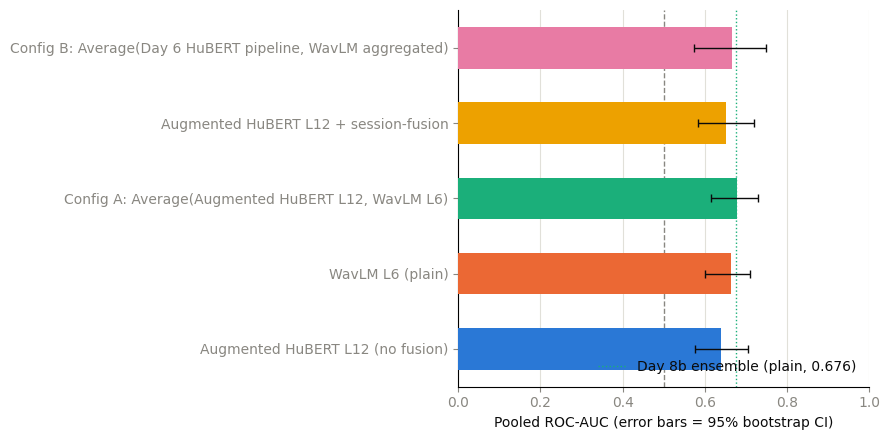


Best Day 8c configuration: Config A: Average(Augmented HuBERT L12, WavLM L6)  AUC=0.678  CI=[0.615, 0.730]
No permutation test run here -- reserved for Day 10's final buffer.


In [11]:
results_df = pd.DataFrame(results_log)
print(results_df.to_string(index=False))

DAY8C_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#2a78d6"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

fig, ax = plt.subplots(figsize=(9, 4.5))
y_pos = np.arange(len(results_df))
ax.barh(y_pos, results_df["auc"], color=DAY8C_COLORS[: len(results_df)], height=0.55, zorder=3)
ax.errorbar(
    results_df["auc"], y_pos,
    xerr=[results_df["auc"] - results_df["ci_lo"], results_df["ci_hi"] - results_df["auc"]],
    fmt="none", ecolor=INK, elinewidth=1, capsize=3, zorder=4,
)
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--", zorder=2)
ax.axvline(0.676, color="#1baf7a", linewidth=1, linestyle=":", zorder=2, label="Day 8b ensemble (plain, 0.676)")
ax.set_yticks(y_pos)
ax.set_yticklabels(results_df["variant"], color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("Pooled ROC-AUC (error bars = 95% bootstrap CI)", color=INK)
ax.tick_params(colors=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, labelcolor=INK, loc="lower right")
plt.tight_layout()
plt.show()

best_idx = results_df["auc"].idxmax()
print(f"\nBest Day 8c configuration: {results_df.loc[best_idx, 'variant']}  "
      f"AUC={results_df.loc[best_idx, 'auc']:.3f}  "
      f"CI=[{results_df.loc[best_idx, 'ci_lo']:.3f}, {results_df.loc[best_idx, 'ci_hi']:.3f}]")
print("No permutation test run here -- reserved for Day 10's final buffer.")

## How to read Day 8c's results

- **Config A and/or B clearly beat Day 8b's plain ensemble (0.676)**, CI lower bound moving up too:
  feeding the ensemble a better-tuned HuBERT pipeline helps further -- this becomes the new
  front-runner for Day 10's shortlist.
- **Config A/B land close to 0.676 with heavily overlapping CIs**: swapping in the improved HuBERT
  pipeline doesn't clearly help the ensemble beyond what plain HuBERT already provided -- plausible
  if augmented/fused HuBERT's *errors* correlate more with WavLM's than plain HuBERT's did (a
  stronger but more redundant signal contributes less to an average than an independently-different,
  weaker one). Day 8b's plain ensemble remains the carried-forward candidate, per Simplicity First.
- **Config A/B land below 0.676**: reinforces the "redundancy over strength" explanation above more
  strongly, and is a genuinely informative negative result about *why* Day 8b's ensemble worked in
  the first place -- worth stating plainly in the write-up, not just discarding.
- **Config A vs. Config B diverge noticeably**: informative about grain -- if B (session-grain,
  Day 6's actual confirmed pipeline) beats A (recording-grain, simpler augmented-only HuBERT), that
  suggests session-fusion's complementary-activity-evidence benefit (Day 1/6's original finding)
  carries through into the ensemble too, not just the standalone HuBERT pipeline.

**No permutation test yet.** Update `PROJECT_PLAN.md`'s Day 7+ roadmap section with today's numbers,
then decide Day 9's exact shape based on whichever configuration (Day 8b's plain ensemble, or one of
today's) is the actual front-runner.